# Lecture 2: Cass-Koopmans with Capital and Labour Adjustment Costs

**Lecture 2 of 9** · [Series index](README.md)

*This lecture builds on [Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method](01_cass_koopmans_competitive_equilibrium.ipynb), which adapts [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) and [Cass-Koopmans Planning Model](https://python.quantecon.org/cass_koopmans_1.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)). It is shared under the same licence. The Newton solver used throughout is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0.*

## Overview

In [Lecture 1](01_cass_koopmans_competitive_equilibrium.ipynb) we solved a one-sector growth model three ways — as a planning problem, as a date-0 market economy and as a sequential market economy — and found the same allocation and prices each time.

This lecture extends that economy in three directions:

1. **Capital adjustment costs.** Changing the capital stock quickly uses up goods. The firm's installed capital acquires a shadow value that differs from the price of new investment goods — **Tobin's $q$**.
2. **Elastic labour supply.** The household values leisure, so employment is an endogenous choice rather than fixed at $N = 1$.
3. **Labour adjustment costs.** Changing employment quickly is also costly. These costs only bite if employment can move, which is why we need elastic labour supply.

We solve the model in two ways, using the same Newton routine as before:

- as a **decentralised price system**, organised the way a computable general equilibrium (CGE) model is: prices and quantities are Newton unknowns, firms price at marginal cost, the household solves a two-stage consumption-leisure problem, and markets clear, and
- as a **planning problem**, written independently, which we use as a cross-check.

The two coincide to machine precision, so the welfare theorems survive adjustment costs: the costs are real resource costs, not distortions.

Along the way we meet a different **closure** from Lecture 1. There, the goods price was $1$ in every period and interest rates moved. Here, as is common in CGE models, the interest rate is fixed at $1/\beta - 1$ and the goods price $p_{y,t}$ moves. The two are equivalent normalisations, and we show how to translate between them.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from collections import namedtuple

jax.config.update("jax_enable_x64", True)

## The model

Time is discrete, $t = 0, 1, \ldots, T$. As in [Lecture 1](01_cass_koopmans_competitive_equilibrium.ipynb) there is a single good that can be consumed or invested, capital depreciates at rate $\delta$, and the economy starts with capital $k_0$ below its steady state.

### Preferences

The household has a time endowment $H$, works $n_t$ and enjoys leisure $l_t = H - n_t$. Consumption and leisure combine into a Cobb-Douglas composite

$$
u_t = c_t^{a}\, l_t^{1-a}
$$

and the household ranks plans by

$$
\sum_{t=0}^{T} \beta^t \frac{u_t^{1-\gamma}}{1-\gamma}
$$

With $\gamma$ governing the willingness to substitute the composite over time and $a$ governing the split between consumption and leisure within a period. Setting $a = 1$ and $n_t = 1$ recovers the Cass-Koopmans preferences.

### Technology and adjustment costs

Gross output is produced from capital and labour,

$$
Y_t = A k_t^{\alpha} n_t^{1-\alpha}
$$

Part of gross output is used up by adjustment costs; the rest, **delivered output** $y_t$, is available for consumption and investment:

$$
Y_t = y_t + AC_t + LAC_t, \qquad y_t = c_t + I_t, \qquad I_t = k_{t+1} - (1-\delta) k_t
$$

The capital adjustment cost is

$$
AC_t = \frac{\zeta}{2}\, k_t \left(\frac{k_{t+1}}{k_t} - 1\right)^2 = \frac{\zeta}{2}\, k_t \left(\frac{I_t}{k_t} - \delta\right)^2
$$

It is zero when investment just replaces depreciation and grows with the square of net investment relative to the capital stock.

The labour adjustment cost is

$$
LAC_t = \frac{\zeta_n}{2}\, n_t \left(\frac{n_t}{n_{t-1}} - 1\right)^2
$$

with employment before the start of the model, $n_{-1}$, given. We set $n_{-1}$ to its steady-state value, so employment cannot jump freely at $t = 0$.

### Boundary conditions

As in Lecture 1 we impose $k_{T+1} = k_{ss}$. For labour we assume there is no adjustment after $T$, i.e. $n_{T+1} = n_T$, so the cost $LAC_{T+1}$ is zero and the period-$T$ hiring decision has no future adjustment consequences.

### Steady state and calibration

Adjustment costs are zero in a steady state, so the steady state is the one of the frictionless model. The capital-labour ratio $\kappa = k/n$ is pinned down by $\alpha A \kappa^{\alpha - 1} = 1/\beta - (1 - \delta)$, which gives output, consumption and the wage per worker.

Rather than choosing the consumption weight $a$ directly, we choose a target for steady-state employment, $n_{ss} = H/3$, and back out the $a$ that delivers it from the household's consumption-leisure condition

$$
\frac{1-a}{a}\, \frac{c}{l} = w \quad \Longrightarrow \quad a = \left(1 + \frac{H - n_{ss}}{n_{ss}} \frac{w}{c/n}\right)^{-1}
$$

In [2]:
LabSettings = namedtuple('LabSettings', ['beta', 'gamma', 'delta', 'alpha', 'A', 'T', 'k0', 'zeta',
                                         'zeta_n', 'H', 'a', 'n0', 'k_ss', 'n_ss', 'c_ss'])


def get_settings(beta=0.95, gamma=2.0, delta=0.02, alpha=0.33, A=1.0, T=200, k0_frac=0.3,
                 zeta=5.0, zeta_n=2.0, H=1.0, n_target=1 / 3):
    # Steady state has employment n_ss = n_target * H; the consumption weight a is calibrated to deliver it.
    kappa = ((1 / beta - (1 - delta)) / (alpha * A)) ** (1 / (alpha - 1))      # k/n in steady state
    y_n = A * kappa ** alpha
    c_n = y_n - delta * kappa
    w_ss = (1 - alpha) * y_n
    n_ss = n_target * H
    a = 1 / (1 + (H - n_ss) / n_ss * w_ss / c_n)
    k_ss, c_ss = kappa * n_ss, c_n * n_ss
    return LabSettings(beta, gamma, delta, alpha, A, T, k0_frac * k_ss, zeta, zeta_n, H, a, n_ss, k_ss, n_ss, c_ss)


s = get_settings()
print(f'a = {s.a:.4f}, k_ss = {s.k_ss:.4f}, n_ss = {s.n_ss:.4f}, c_ss = {s.c_ss:.4f}, k_0 = {s.k0:.4f}')

a = 0.4042, k_ss = 3.1919, n_ss = 0.3333, c_ss = 0.6387, k_0 = 0.9576


### Adjustment-cost functions

Both the planner and the price system need the adjustment costs and their derivatives. For capital, with $g_t = k_{t+1}/k_t$:

$$
\frac{\partial AC_t}{\partial k_{t+1}} = \zeta (g_t - 1), \qquad
\frac{\partial AC_t}{\partial k_t} = \frac{\zeta}{2}\left(1 - g_t^2\right)
$$

The second is negative whenever capital is growing ($g_t > 1$): for given $k_{t+1}$, a larger $k_t$ means less net investment and so lower adjustment costs.

For labour, with $g^n_t = n_t / n_{t-1}$:

$$
\frac{\partial LAC_t}{\partial n_t} = \frac{\zeta_n}{2} (g^n_t - 1)^2 + \zeta_n g^n_t (g^n_t - 1), \qquad
\frac{\partial LAC_t}{\partial n_{t-1}} = -\zeta_n (g^n_t - 1) (g^n_t)^2
$$

Hiring at $t$ raises today's adjustment cost but, if employment is growing, lowers tomorrow's.

The arrays below are indexed $t = 0, \ldots, T$. For labour we pass the extended vector $(n_{-1}, n_0, \ldots, n_T)$.

In [3]:
# ----- capital adjustment costs (same functional forms as adjustment_cost / adjust_cost_t /
# adjust_cost_t1 in cge_lucas.py, with trend growth = 0, in 1D). k = (k_0..k_{T+1}), g_t = k_{t+1}/k_t.
def adjustment_cost(k, s):
    """AC_t = zeta k_t/2 (k_{t+1}/k_t - 1)^2, paid in goods; t = 0..T."""
    return s.zeta * k[:-1] / 2 * (k[1:] / k[:-1] - 1) ** 2


def adjust_cost_t(k, s):
    """dAC_t/dk_{t+1} = zeta (g_t - 1): extra cost of installing capital at t."""
    return s.zeta * (k[1:] / k[:-1] - 1)


def adjust_cost_t1(k, s):
    """dAC_{t+1}/dk_{t+1} = zeta/2 (1 - g_{t+1}^2): adjustment cost saved next period by having more capital."""
    return s.zeta / 2 * (1 - (k[1:] / k[:-1]) ** 2)


# ----- labour adjustment costs;  n_ext = (n_{-1}, n_0..n_T),  outputs indexed t = 0..T -----
def labour_adj_cost(n_ext, s):
    return s.zeta_n * n_ext[1:] / 2 * (n_ext[1:] / n_ext[:-1] - 1) ** 2


def labour_adj_cost_prime_t(n_ext, s):
    # dLAC_t / dn_t
    g = n_ext[1:] / n_ext[:-1]
    return s.zeta_n / 2 * (g - 1) ** 2 + s.zeta_n * g * (g - 1)


def labour_adj_cost_prime_t1(n_ext, s):
    # dLAC_t / dn_{t-1}  (what the firm saves one period earlier by having more labour at t-1)
    g = n_ext[1:] / n_ext[:-1]
    return -s.zeta_n * (g - 1) * g ** 2


def lead(z):
    # z_{t+1}, with z_{T+1} = 0 (no labour adjustment after T)
    return jnp.concatenate([z[1:], jnp.zeros(1)])

### Newton's method

We use the same damped-then-full Newton routine as [Lecture 1](01_cass_koopmans_competitive_equilibrium.ipynb): JAX supplies the exact Jacobian by automatic differentiation, a run of damped steps brings the iterates close, and full steps then converge quadratically. The routine is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html).

In [4]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=False):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x

## The planning problem

A planner chooses $\{c_t, n_t, k_{t+1}\}$ to maximise utility subject to

$$
k_{t+1} = A k_t^\alpha n_t^{1-\alpha} + (1-\delta) k_t - c_t - AC_t - LAC_t
$$

Let $U_{c,t}$ and $U_{l,t}$ be the marginal utilities of consumption and leisure:

$$
U_{c,t} = a \frac{u_t^{1-\gamma}}{c_t}, \qquad U_{l,t} = (1-a) \frac{u_t^{1-\gamma}}{l_t}
$$

and let $f_{k,t}$ and $f_{n,t}$ be the marginal products of capital and labour. The first-order conditions are

**Capital Euler equation** ($t = 0, \ldots, T-1$). One more unit of $k_{t+1}$ costs $1 + \partial AC_t / \partial k_{t+1}$ goods today and yields the marginal product, undepreciated capital, and a saving on next period's adjustment cost tomorrow:

$$
U_{c,t}\left(1 + \frac{\partial AC_t}{\partial k_{t+1}}\right)
= \beta U_{c,t+1}\left(f_{k,t+1} + 1 - \delta - \frac{\partial AC_{t+1}}{\partial k_{t+1}}\right)
$$

**Labour** ($t = 0, \ldots, T$). The marginal product of labour, net of the adjustment cost incurred today and of the discounted effect on tomorrow's adjustment cost, equals the marginal rate of substitution between leisure and consumption:

$$
f_{n,t} - \frac{\partial LAC_t}{\partial n_t} - \beta \frac{U_{c,t+1}}{U_{c,t}} \frac{\partial LAC_{t+1}}{\partial n_t} = \frac{U_{l,t}}{U_{c,t}}
$$

**Resource constraint** ($t = 0, \ldots, T$), as above.

That is $3T + 2$ equations in $c_0, \ldots, c_T$, $n_0, \ldots, n_T$ and $k_1, \ldots, k_T$, which we stack in logs and solve with Newton. The planner's Hicks-Arrow prices are $q_t^0 = \beta^t U_{c,t} / U_{c,0}$.

In [5]:
def planner_solve(x, s, solving=1):
    n = s.T + 1
    c, nl = jnp.exp(x[:n]), jnp.exp(x[n:2 * n])
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[2 * n:]), jnp.array([s.k_ss])])
    ks = k[:-1]
    ac = adjustment_cost(k, s)
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac, d_t, d_t1 = (labour_adj_cost(n_ext, s), labour_adj_cost_prime_t(n_ext, s),
                      labour_adj_cost_prime_t1(n_ext, s))

    l = s.H - nl
    uu = c ** s.a * l ** (1 - s.a)
    Uc = s.a * uu ** (1 - s.gamma) / c
    Ul = (1 - s.a) * uu ** (1 - s.gamma) / l
    f = s.A * ks ** s.alpha * nl ** (1 - s.alpha)
    fk = s.alpha * s.A * (ks / nl) ** (s.alpha - 1)
    fn = (1 - s.alpha) * s.A * (ks / nl) ** s.alpha

    resource = k[1:] - (f + (1 - s.delta) * ks - c - ac - lac)
    adj_t, adj_t1 = adjust_cost_t(k, s), adjust_cost_t1(k, s)
    euler_k = (jnp.log(Uc[:-1] * (1 + adj_t[:-1]))
               - jnp.log(s.beta * Uc[1:] * (fk[1:] + 1 - s.delta - adj_t1[1:])))
    labour_foc = (fn - d_t) - s.beta * lead(Uc) / Uc * lead(d_t1) - Ul / Uc

    errors = jnp.concatenate([resource, euler_k, labour_foc])
    if solving:
        return errors
    return errors, dict(c=c, n=nl, k=k, q=s.beta ** np.arange(n) * Uc / Uc[0])


def run_planner(verbose=True, **kwargs):
    s = get_settings(**kwargs)
    n = s.T + 1
    f = lambda x: planner_solve(x, s, 1)
    k_path = np.linspace(s.k0, s.k_ss, s.T + 2)[1:-1]
    x0 = np.log(np.hstack((s.c_ss * np.ones(n), s.n_ss * np.ones(n), k_path)))
    x1 = newton(f, x0, tol=1e-6, max_iter=1000, adj=0.3)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, plan = planner_solve(x, s, 0)
    plan = {k_: np.asarray(v) for k_, v in plan.items()}
    plan['residual'] = float(jnp.max(jnp.abs(errors)))
    if verbose:
        print(f'planner max |residual| = {plan["residual"]:.2e}')
    return plan

## The decentralised price system

Now we organise the same economy as a market economy, in the style of a CGE model. There is a representative firm and a representative household, both price takers.

### Closure and numeraire

In [Lecture 1](01_cass_koopmans_competitive_equilibrium.ipynb) the good was the numeraire in every period: its price was $1$ at each date, and the interest rate $r_t$ moved over the transition.

Here we follow a common CGE convention instead. The **interest rate is fixed** at its steady-state value,

$$
r = \frac{1}{\beta} - 1
$$

and the **goods price** $p_{y,t}$ moves, with $p_{y,0} = 1$ as numeraire. Prices are then in units of a "dollar" that earns interest $r$, and all the intertemporal price movement shows up in $p_{y,t}$.

Nothing real depends on this choice. The Hicks-Arrow price of the time-$t$ good in units of the time-0 good is the dollar price of the good, discounted back to $t = 0$:

$$
q_t^0 = \frac{p_{y,t}}{(1+r)^t}
$$

and the **real** interest rate between $t$ and $t+1$ is

$$
1 + r^{\text{real}}_t = (1 + r)\, \frac{p_{y,t}}{p_{y,t+1}}
$$

When capital is scarce and the real rate is high, $p_{y,t}$ falls over time faster than $(1+r)^{-1}$ would suggest; in steady state $p_{y,t}$ is constant and $r^{\text{real}} = r$. (I'm not so sure about this)

### The firm

The firm owns the capital stock, hires labour at wage $w_t$, invests, and pays its cash flow to the household as dividends. It maximises the present value of dividends discounted at $r$.

**Pricing.** The firm prices delivered output at marginal cost: $p_{y,t} = p^{bt}_{y,t}$, where $p^{bt}_{y,t}$ is the marginal cost of gross output.

**Labour demand.** Hiring a worker at $t$ costs the wage plus the marginal labour adjustment cost

$$
MLAC_t = p_{y,t} \frac{\partial LAC_t}{\partial n_t} + \frac{p_{y,t+1}}{1+r}\frac{\partial LAC_{t+1}}{\partial n_t}
$$

so the effective price of labour input is $p_{n,t} = w_t + MLAC_t$. When the firm is expanding, $MLAC_t > 0$: hiring is expensive today, partly offset by lower adjustment costs tomorrow. The labour first-order condition sets the value of labour's marginal product equal to its effective price,

$$
p^{bt}_{y,t}\, (1-\alpha) \frac{Y_t}{n_t} = p_{n,t}
$$

which, read the other way, defines marginal cost given the price of labour.

**Capital services.** The value of capital's marginal product is the **price of capital services**

$$
p_{ks,t} = p^{bt}_{y,t}\, \alpha \frac{Y_t}{k_t}
$$

**Investment and Tobin's $q$.** Installing one more unit of capital costs the price of the investment good, $p_{i,t} = p_{y,t}$, plus the marginal adjustment cost. That is the shadow price of installed capital, which we write $Q_t$ (`q` in the code):

$$
Q_t = p_{i,t} + p_{y,t}\, \zeta \left(\frac{I_t}{k_t} - \delta\right)
$$

**Tobin's $q$** is the ratio $Q_t / p_{i,t}$. It exceeds $1$ when the firm is building up capital, and equals $1$ in steady state or when $\zeta = 0$.

The capital first-order condition is a no-arbitrage condition: the return from buying a unit of installed capital at $Q_t$ must equal the interest rate. Holding a unit of capital from $t$ to $t+1$ earns the rental value of capital services, a reduction in next period's adjustment cost, and the resale value of the undepreciated unit:

$$
\frac{p_{ks,t+1} + \tfrac{1}{2}\zeta\, p_{y,t+1}\left[\left(\frac{I_{t+1}}{k_{t+1}}\right)^2 - \delta^2\right] + (1-\delta)\, Q_{t+1} - Q_t}{Q_t} = r
$$

The middle term is $-p_{y,t+1}\, \partial AC_{t+1} / \partial k_{t+1}$, holding investment fixed.

**Dividends** are the firm's cash flow,

$$
\text{div}_t = p_{y,t} y_t - w_t n_t - p_{i,t} I_t
= p_{ks,t} k_t + MLAC_t\, n_t - p_{y,t}(AC_t + LAC_t) - p_{i,t} I_t
$$

where the second form uses marginal-cost pricing and constant returns ($p^{bt}_{y,t} Y_t = p_{ks,t} k_t + p_{n,t} n_t$).

### The household

The household owns the firm, supplies labour, and buys consumption at $p_{c,t} = p_{y,t}$. Its problem splits into two stages.

**Static stage: consumption versus leisure.** Leisure costs the wage, $p_{l,t} = w_t$. Because the composite $u_t$ is Cobb-Douglas, the unit cost of utility is

$$
p_{u,t} = \left(\frac{p_{c,t}}{a}\right)^{a} \left(\frac{p_{l,t}}{1-a}\right)^{1-a}
$$

and, given $u_t$, the demands are

$$
c_t = a \frac{p_{u,t} u_t}{p_{c,t}}, \qquad l_t = (1-a) \frac{p_{u,t} u_t}{p_{l,t}}, \qquad N^s_t = H - l_t
$$

**Dynamic stage: utility over time.** The household chooses the path of $u_t$, each unit costing $p_{u,t}$ dollars, with dollars earning interest $r$. The first-order condition $\beta^t u_t^{-\gamma} = \lambda\, p_{u,t} / (1+r)^t$ gives the Euler equation

$$
\frac{u_{t+1}}{u_t} = \left(\beta (1+r) \frac{p_{u,t}}{p_{u,t+1}}\right)^{1/\gamma}
$$

### Market clearing and Walras' law

The markets are

$$
\text{Labour:}\ N^s_t = n_t, \qquad \text{Goods:}\ c_t + I_t = y_t
$$

and gross output must equal what the production function delivers.

The household's budget constraint, $p_{c,t} c_t = w_t n_t + \text{div}_t$, is not imposed: it follows from the goods market, marginal-cost pricing and the definition of dividends. That is Walras' law, and we report the budget as a check.

### The stacked system

| Block | Equation | Periods | Count |
|---|---|---|---|
| Price (marginal-cost pricing) | $p_{y,t} = p^{bt}_{y,t}$ | $0..T$ | $T+1$ |
| Production | $\log Y_t = \log(A k_t^\alpha n_t^{1-\alpha})$, with $Y_t = y_t + AC_t + LAC_t$ | $0..T$ | $T+1$ |
| Labour market | $N^s_t = n_t$ | $0..T$ | $T+1$ |
| Goods market | $c_t + I_t = y_t$ | $0..T$ | $T+1$ |
| Household Euler | $\log u_{t+1} - \log u_t = \frac{1}{\gamma}\log\left(\beta(1+r) p_{u,t}/p_{u,t+1}\right)$ | $0..T-1$ | $T$ |
| Capital (no arbitrage) | return on installed capital $= r$ | $0..T-1$ | $T$ |

That is $6T + 4$ equations. The unknowns, all in logs, are $p_{y,1}, \ldots, p_{y,T}$ ($p_{y,0} = 1$), and $w_t, u_t, y_t, n_t$ for $t = 0, \ldots, T$, plus $k_1, \ldots, k_T$: also $6T + 4$.

Everything else — marginal cost, the price of capital services, $MLAC_t$, Tobin's $q$, consumption and leisure — is computed from these in a **price block**, just as a CGE model computes derived prices and demands before evaluating its market-clearing residuals.

In [6]:
def MLAC(n_ext, p_y, s, r):
    # Marginal labour adjustment cost: p_t dLAC_t/dn_t + p_{t+1}/(1+r) dLAC_{t+1}/dn_t
    p_next = jnp.concatenate([p_y[1:], p_y[-1:]])
    return (p_y * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + r))


def unpack(x, s):
    T, n = s.T, s.T + 1
    p_y = jnp.concatenate([jnp.ones(1), jnp.exp(x[:T])])             # numeraire: p_y_0 = 1
    w, u, y, nl = (jnp.exp(x[T + i * n:T + (i + 1) * n]) for i in range(4))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[T + 4 * n:]), jnp.array([s.k_ss])])   # k_0..k_{T+1}
    return p_y, w, u, y, nl, k


def price_block(p_y, w, u, y, nl, k, s, r):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = MLAC(n_ext, p_y, s, r)

    y_bt = y + ac + lac                                      # gross output produced
    p_n = w + mlac                                           # price of labour input (wage + shadow adjustment cost)
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)               # marginal cost
    p_ks = p_y_bt * s.alpha * y_bt / ks                      # capital services price
    p_c = p_y
    p_i = p_y

    # household static problem (Cobb-Douglas consumption-leisure)
    p_l = w
    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    N_supply = s.H - leisure

    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p_y * s.zeta * (invest / ks - s.delta)         # shadow price of installed capital
    return dict(ac=ac, lac=lac, mlac=mlac, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, p_c=p_c, p_i=p_i,
                p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=N_supply, I=invest, q=q)

The residual function evaluates the price block and then each error block. Price, labour and goods errors are scaled relative to their levels so that all blocks are of comparable size.

In [7]:
def transition_economy(x, s, solving=1):
    p_y, w, u, y, nl, k = unpack(x, s)
    r = 1 / s.beta - 1
    P = price_block(p_y, w, u, y, nl, k, s, r)

    price_error = (p_y - P['p_y_bt']) / p_y
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * k[:-1] ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] - y) / y

    sigma = 1 / s.gamma
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - sigma * jnp.log(s.beta * (1 + r) * P['p_u'][:-1] / P['p_u'][1:]))

    ik, q = P['I'] / k[:-1], P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p_y[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    capital_error = r_implied - r

    errors = jnp.concatenate([price_error, production_error, labour_error, goods_error,
                              household_error, capital_error])
    if solving:
        return errors

    div = P['p_ks'] * k[:-1] + P['mlac'] * nl - p_y * (P['ac'] + P['lac']) - P['p_i'] * P['I']
    budget = P['p_c'] * P['c'] - (w * nl + div)                    # Walras check, should be ~0
    econ = dict(P, p_y=p_y, w=w, u=u, y=y, n=nl, k=k, div=div, budget=budget, r=r,
                tobin_q=q / P['p_i'], real_w=w / P['p_c'], real_ks=P['p_ks'] / P['p_c'],
                r_real=(1 + r) * p_y[:-1] / p_y[1:] - 1)
    return errors, econ

The initial guess puts every price and quantity at its steady-state value, except capital, which runs in a straight line from $k_0$ to $k_{ss}$.

In [8]:
def initial_guess(s):
    n = s.T + 1
    kappa = s.k_ss / s.n_ss
    y_ss = s.A * kappa ** s.alpha * s.n_ss
    w_ss = (1 - s.alpha) * y_ss / s.n_ss
    u_ss = s.c_ss ** s.a * (s.H - s.n_ss) ** (1 - s.a)
    k_path = np.linspace(s.k0, s.k_ss, s.T + 2)[1:-1]
    return np.log(np.hstack((np.ones(s.T), w_ss * np.ones(n), u_ss * np.ones(n), y_ss * np.ones(n),
                             s.n_ss * np.ones(n), k_path)))


def run_model(verbose=True, **kwargs):
    s = get_settings(**kwargs)
    f = lambda x: transition_economy(x, s, 1)
    x0 = initial_guess(s)
    if verbose:
        print(f'initial max |residual| = {float(jnp.max(jnp.abs(f(x0)))):.2e}')
    x1 = newton(f, x0, tol=1e-6, max_iter=1000, adj=0.3)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1, verbose=verbose)

    errors, econ = transition_economy(x, s, 0)
    econ = {k_: np.asarray(v) for k_, v in econ.items()}
    econ['residual'] = float(jnp.max(jnp.abs(errors)))
    if verbose:
        print(f'max |error block| = {econ["residual"]:.2e}')
        print(f'max |household budget (Walras)| = {np.max(np.abs(econ["budget"])):.2e}')
    return s, econ

## Solving the baseline economy

The baseline has capital adjustment costs $\zeta = 5$ and labour adjustment costs $\zeta_n = 2$, with $T = 200$ and $k_0 = 0.3\, k_{ss}$. The horizon is long enough that, by the **turnpike** property from Lecture 1, the economy is essentially at its steady state well before $T$, so the terminal condition $k_{T+1} = k_{ss}$ has no visible effect on the transition.

In [9]:
kw = dict(zeta=5.0, zeta_n=2.0)
s, econ = run_model(**kw)
print(f'\n{6 * s.T + 4} unknowns')

initial max |residual| = 3.98e-01


iteration 1, error = 1.9429648457169305e-06
iteration 2, error = 1.1903468226837374e-13


max |error block| = 3.42e-15
max |household budget (Walras)| = 7.22e-16

1204 unknowns


All error blocks are zero to machine precision, and the household's budget holds even though it is not in the system.

### Cross-check against the planner

The planner's problem above was written independently: it never mentions $p_{y,t}$, $MLAC_t$, Tobin's $q$ or dividends. If the price system is right, the two should agree on the allocation, and the price system's discounted goods prices $p_{y,t}/(1+r)^t$ should equal the planner's Hicks-Arrow prices $\beta^t U_{c,t}/U_{c,0}$.

In [10]:
def compare_with_planner(s, econ, verbose=True, **kwargs):
    plan = run_planner(verbose=verbose, **kwargs)
    t = np.arange(s.T + 1)
    q_from_p = econ['p_y'] / (1 + econ['r']) ** t
    diffs = {'c': np.max(np.abs(econ['c'] - plan['c'])),
             'n': np.max(np.abs(econ['n'] - plan['n'])),
             'k': np.max(np.abs(econ['k'] - plan['k'])),
             'p_y/(1+r)^t - q_t': np.max(np.abs(q_from_p - plan['q']))}
    if verbose:
        print('--- price system vs planner ---')
        for name, d in diffs.items():
            print(f'max |{name} diff| = {d:.2e}')
    return max(diffs.values())


compare_with_planner(s, econ, **kw);

planner max |residual| = 3.85e-15
--- price system vs planner ---
max |c diff| = 8.88e-16
max |n diff| = 2.22e-16
max |k diff| = 7.99e-15
max |p_y/(1+r)^t - q_t diff| = 6.66e-16


The price system and the planner coincide. Adjustment costs are real costs of changing capital and employment, not wedges between private and social returns, so the competitive equilibrium is still efficient.

## The role of labour adjustment costs

We compare the baseline with an economy that has the same capital adjustment costs but no labour adjustment costs ($\zeta_n = 0$).

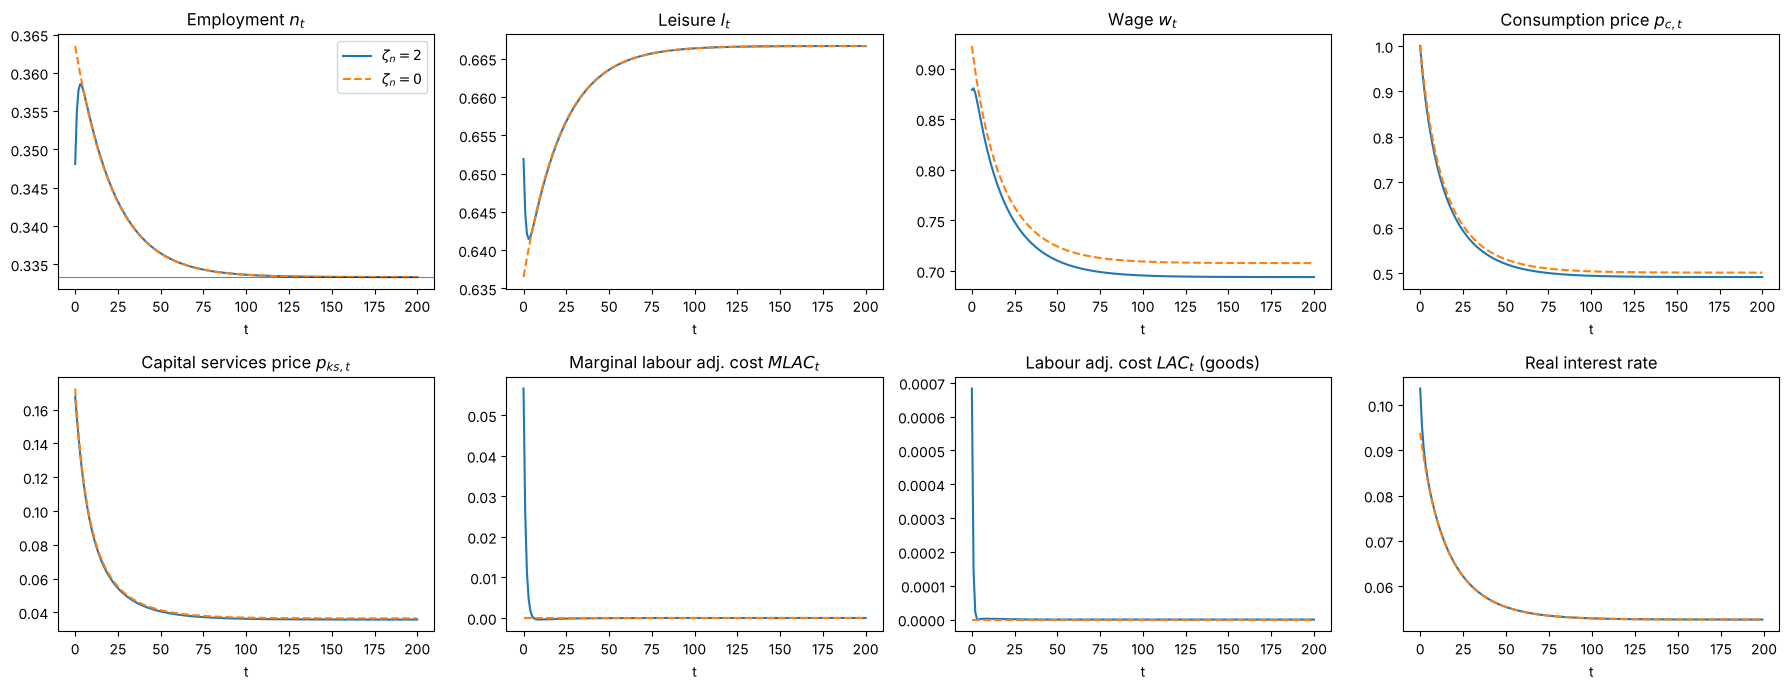

In [11]:
def plot_compare(econs, labels, series, ncols=4, ss=None):
    nrows = int(np.ceil(len(series) / ncols))
    fig, ax = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.5 * nrows))
    styles = ['-', '--', ':', '-.']
    for a_, (title, key) in zip(ax.flat, series):
        for e, lab, ls in zip(econs, labels, styles):
            a_.plot(e[key], ls=ls, label=lab)
        if ss is not None and key in ss:
            a_.axhline(ss[key], color='k', lw=0.8, alpha=0.5)
        a_.set_title(title)
        a_.set_xlabel('t')
    for a_ in ax.flat[len(series):]:
        a_.axis('off')
    ax.flat[0].legend()
    plt.tight_layout()
    plt.show()


_, econ_no_lac = run_model(verbose=False, zeta=5.0, zeta_n=0.0)

plot_compare([econ, econ_no_lac], [r'$\zeta_n = 2$', r'$\zeta_n = 0$'],
             [('Employment $n_t$', 'n'), ('Leisure $l_t$', 'l'), ('Wage $w_t$', 'w'),
              ('Consumption price $p_{c,t}$', 'p_c'), ('Capital services price $p_{ks,t}$', 'p_ks'),
              ('Marginal labour adj. cost $MLAC_t$', 'mlac'), ('Labour adj. cost $LAC_t$ (goods)', 'lac'),
              ('Real interest rate', 'r_real')],
             ss={'n': s.n_ss})

The economy starts with too little capital. That makes the household poorer than in steady state, so it consumes less leisure and works more: employment is above its steady-state level of $1/3$ for the whole transition and falls as capital accumulates.

- **Without labour adjustment costs** ($\zeta_n = 0$), employment jumps up at $t = 0$ and then declines monotonically.
- **With labour adjustment costs**, the jump is costly. Employment starts from its pre-period level $n_{-1} = n_{ss}$ and rises gradually over the first few periods before declining, so the path is hump-shaped and smoother.

$MLAC_t$ is large while the firm is hiring in the first few periods and close to zero afterwards, when employment changes only slowly. The wedge it drives between the wage and the effective cost of labour is what holds back hiring at the start. The goods actually used up by labour adjustment, $LAC_t$, are tiny: the firm avoids paying them by spreading the adjustment over time.

Nominal prices such as $w_t$ and $p_{c,t}$ settle at slightly different levels in the two economies. That is only the numeraire: $p_{y,0} = 1$ is fixed in a period whose real conditions differ between the two economies, which shifts every later dollar price. Real prices, such as the real wage $w_t / p_{c,t}$, converge to the same steady state.

The consumption price $p_{c,t} = p_{y,t}$ falls steeply early on. With the dollar interest rate fixed at $r$, that fall is how a high **real** interest rate shows up in this closure: a scarce capital stock earns a high return, and the real rate converges to $1/\beta - 1 \approx 5.3\%$ as capital approaches its steady state.

## The role of capital adjustment costs

Next we turn the capital adjustment cost up and down, holding $\zeta_n = 2$, and include an economy with no adjustment costs at all, which is a Cass-Koopmans economy with elastic labour supply.

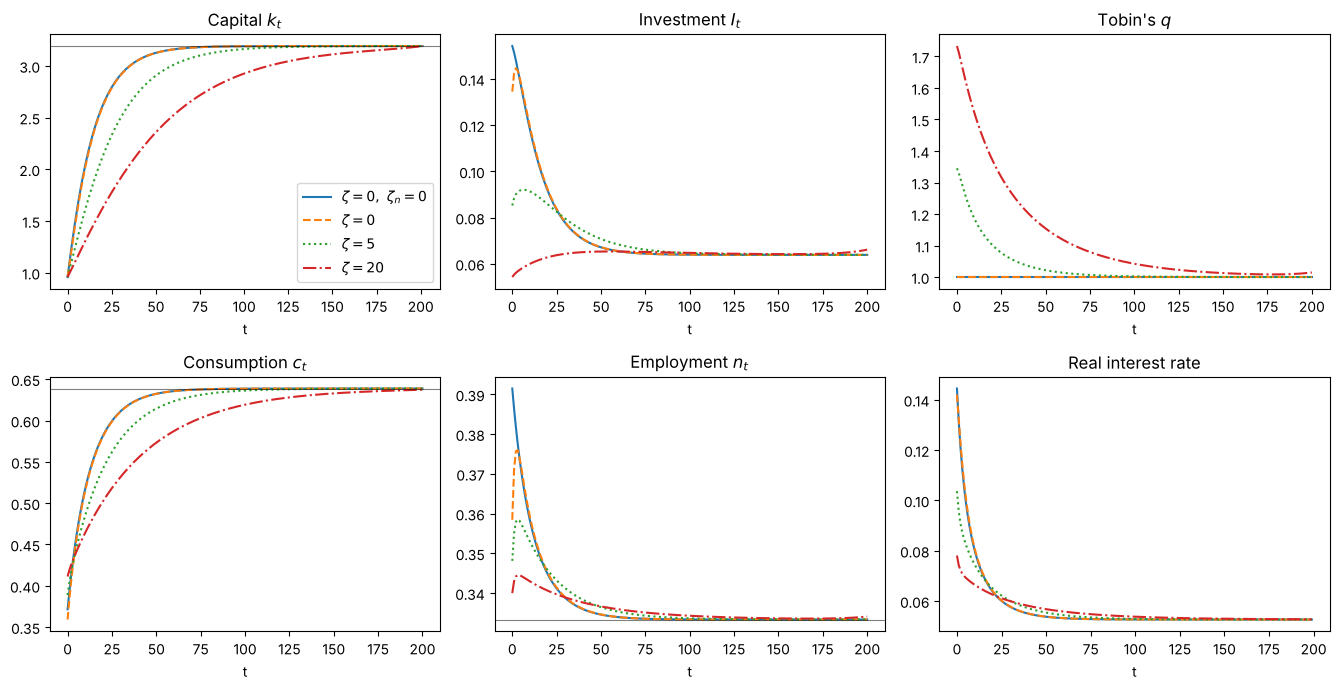

In [12]:
cases = [(r'$\zeta = 0,\ \zeta_n = 0$', dict(zeta=0.0, zeta_n=0.0)),
         (r'$\zeta = 0$', dict(zeta=0.0, zeta_n=2.0)),
         (r'$\zeta = 5$', dict(zeta=5.0, zeta_n=2.0)),
         (r'$\zeta = 20$', dict(zeta=20.0, zeta_n=2.0))]
econs = [run_model(verbose=False, **kw_)[1] for _, kw_ in cases]

plot_compare(econs, [lab for lab, _ in cases],
             [('Capital $k_t$', 'k'), ('Investment $I_t$', 'I'), ("Tobin's $q$", 'tobin_q'),
              ('Consumption $c_t$', 'c'), ('Employment $n_t$', 'n'), ('Real interest rate', 'r_real')],
             ncols=3, ss={'k': s.k_ss, 'n': s.n_ss, 'c': s.c_ss})

Without capital adjustment costs ($\zeta = 0$) Tobin's $q$ is identically $1$: installed capital is worth exactly what new capital costs. The firm invests heavily at once and the capital stock converges quickly.

Adjustment costs make rapid investment expensive, so the firm spreads it out. Investment starts lower and stays elevated for longer, capital converges more slowly, and installed capital is worth more than new capital: Tobin's $q$ starts well above $1$ and declines towards it as the capital gap closes.

Adjustment costs also lower the **real interest rate** early in the transition. Converting goods into capital quickly is costly, so the return the economy can earn on extra saving is lower than the raw marginal product of capital. The household responds by saving less up front: consumption starts higher and rises more slowly, and the initial burst of extra work is smaller.

Comparing the two $\zeta = 0$ economies shows that labour adjustment costs have little effect on capital accumulation: their main effect is on the timing of employment in the first few periods.

## Welfare theorems across parameterisations

Finally we check that the price system reproduces the planner across a range of adjustment costs, and for a shorter horizon ($T = 50$).

In [13]:
check_cases = [dict(zeta=0.0, zeta_n=0.0), dict(zeta=0.0, zeta_n=2.0), dict(zeta=5.0, zeta_n=0.0),
               dict(zeta=5.0, zeta_n=2.0), dict(zeta=20.0, zeta_n=10.0), dict(zeta=5.0, zeta_n=2.0, T=50)]

print(f'{"case":<34s}{"unknowns":>10s}{"max |error|":>14s}{"max |diff| vs planner":>24s}')
for kw_ in check_cases:
    s_, e_ = run_model(verbose=False, **kw_)
    d = compare_with_planner(s_, e_, verbose=False, **kw_)
    name = ', '.join(f'{k_} = {v:g}' for k_, v in kw_.items())
    print(f'{name:<34s}{6 * s_.T + 4:>10d}{e_["residual"]:>14.2e}{d:>24.2e}')

case                                unknowns   max |error|   max |diff| vs planner


zeta = 0, zeta_n = 0                    1204      1.92e-15                9.77e-15


zeta = 0, zeta_n = 2                    1204      2.05e-15                8.88e-15


zeta = 5, zeta_n = 0                    1204      4.03e-15                7.99e-15


zeta = 5, zeta_n = 2                    1204      3.42e-15                7.99e-15


zeta = 20, zeta_n = 10                  1204      1.65e-14                5.77e-15


zeta = 5, zeta_n = 2, T = 50             304      2.84e-15                2.66e-15


In every case the decentralised price system and the planner agree to machine precision.

The CGE-style formulation does more work than the planner here — derived prices, dividends, a two-stage household problem — but that structure is what makes it extensible. Adding distorting taxes, several industries or several household types requires new prices and new market-clearing conditions in the price block, but no change to the solution method. Once taxes enter, the planner's problem no longer describes the equilibrium, and the price system is the only route left.